<a href="https://colab.research.google.com/github/JulioRan09/Porgramacion-Predictiva/blob/main/Rangel_Julio_EDA_predictivo_bank_marketing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** Julio Rangel García  

**Matrícula:** 276572

**Fecha:** 06/10/26

## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |

## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [1]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
COLORES_CLASE = {"no": AZUL, "yes": NARANJA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación? | Cada observación es el contacto de una persona.
| ¿Qué se predice? | `y`: `yes` si el cliente contrata el depósito, `no` si no lo contrata. |
| ¿Qué tipo de problema es? | Clasificación binaria|
| ¿En qué momento se haría la predicción y qué información existiría entonces? | Al tener las características de un nuevo cliente y campaña. Se tendría información relacionada al cliente como `age`, `marital`, `loan`, ente otras, e información sobre la campaña como `campaign`, `previous`, entre otras. |
| ¿Qué columnas no deberían usarse como características y por qué? | En este caso no se tiene identificador de cliente, la única caracterítica que se podría descartar sería `contact`, pero no es concluyente, inclusive esto podría brindar información.|

**Tu predicción.** ¿Qué porcentaje de los contactos esperas que haya terminado en contratación del depósito? Espero un porcentaje menor al 10%, no me parece que este tipo de contrataciones sean comunes.

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.** ¿Habrá valores `NaN`? ¿En qué columnas esperas encontrar `unknown` y en cuántas filas?
Columnas numéricas como `duration`, `campaign` se esperaría tener `NaN` para datos faltantes, si el dataset está depurado, no esperaría encontrar apenas datos nulos. `unknown` sería el equivalente de `NaN`para las columnas categóricas como `default`, `housing`, etc.

In [2]:
df.head(3)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
# B1. Estructura. Escribe el código que muestre:
#  - las dimensiones del conjunto,
#  - el tipo de dato de cada columna,
#  - el número de valores únicos por columna, de menor a mayor.

In [4]:
#B1.
print(f'Las dimensiones del conjunto son: {df.shape} \n')
print(f'El tipo de dato de cada columna es: \n{df.dtypes} \n')
print(f'El número de valores únicos por columna es: \n{df.nunique().sort_values(ascending=False)}')

Las dimensiones del conjunto son: (41188, 21) 

El tipo de dato de cada columna es: 
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object 

El número de valores únicos por columna es: 
duration          1544
euribor3m          316
age                 78
campaign            42
pdays               27
cons.price.idx      26
cons.conf.idx       26
job                 12
nr.employed         11
emp.var.rate        10
month               10
education            8
previous             8
day_of_we

In [5]:
# B2. Valores faltantes. Escribe el código que muestre:
#  - el total de valores NaN del conjunto,
#  - para las columnas categóricas, cuántas filas tienen "unknown" (solo las columnas con al menos una),
#  - ese conteo como porcentaje de las filas.

In [6]:
#Utilizamos primero una suma para los datos nulos de cada columna
print(f'El total de valors NaN del conjunto es: {df.isna().sum().sum()} \n')


# Conteo de "unknown"
unknowns = (df[categoricas] == 'unknown').sum()

# Mostrar solo las columnas con al menos un unknown
unknowns = unknowns[unknowns > 0]

#Agregar los porcentajes
porcentaje_unknown = (unknowns / len(df) * 100).round(2)
unknown_df = pd.DataFrame({
    'Conteo_unknown': unknowns,
    'Porcentaje (%)': porcentaje_unknown
})


print(unknown_df)

El total de valors NaN del conjunto es: 0 

           Conteo_unknown  Porcentaje (%)
job                   330            0.80
marital                80            0.19
education            1731            4.20
default              8597           20.87
housing               990            2.40
loan                  990            2.40


In [7]:
# B3. Duplicados. Escribe el código que cuente las filas completamente idénticas.

In [8]:
print(f'El número de filas completamente duplicadas es: {df.duplicated().sum()} \n')

El número de filas completamente duplicadas es: 12 



In [9]:
# B4. Consistencia entre columnas relacionadas. Escribe el código que muestre:
#  - cuántas filas tienen pdays igual a 999 y qué porcentaje es,

In [10]:
pdays_altos = (df['pdays'] == 999).sum()
porcentaje_pdays_altos = (pdays_altos / len(df) * 100).round(2)

print(f'El número de filas con pdays == 999 es: {pdays_altos} \n')
print(f'El porcentaje de filas con pdays == 999 es: {porcentaje_pdays_altos}% \n')

El número de filas con pdays == 999 es: 39673 

El porcentaje de filas con pdays == 999 es: 96.32% 



In [11]:
#  - una tabla de contingencia entre poutcome y (previous == 0),
#  - una tabla de contingencia entre poutcome y (pdays == 999).
# Pista: pd.crosstab.

In [12]:
cross_previous= pd.crosstab(df['poutcome'], df['previous'] == 0)
print(cross_previous)

previous     False  True 
poutcome                 
failure       4252      0
nonexistent      0  35563
success       1373      0


### Intepretación
En esta cross table, tenemos en las filas las tres posibilidades de resultado de una campaña anterior: `failure` `noexistent` `success`, y en las columnas tenemos `True` para clientes que NO fueron previamente contactados y `False`para los que SÍ han sido previamente contactados por otras campañas.

Basándonos en la lógica, toda la gente que NUNCA ha sido contactados (`previous` == 0 => `True`), deben de tener `nonexistent` en `poutcome`. Que es precisamente lo que pasa. El caso contrario se distribuye entre `failure` y `success`.

In [13]:
cross_pdays = pd.crosstab(df['poutcome'], df['pdays'] == 999)
print(cross_pdays)

pdays        False  True 
poutcome                 
failure        142   4110
nonexistent      0  35563
success       1373      0


### Interpretacion

De manera similar, por lógica, todos los valores con `pdays` == 999 => `True`, deberían aparecer como `nonexistent` ya que son clientes que no han sido previamente contactados. En este caso, parece que tenemos error de registro en 4110 datos que ponen `poutcome`como `failure`pero tienen 999 en `padys`cuando deberían tener algún número diferente.

In [14]:
# B5. Rangos según el dominio. Escribe el código que muestre:
#  - la edad mínima y máxima,

In [15]:
edad_min = df['age'].min()
edad_max = df['age'].max()

print(f'La edad mínima es: {edad_min}')
print(f'La edad máxima es: {edad_max}')

La edad mínima es: 17
La edad máxima es: 98


In [16]:
#  - cuántas llamadas tienen duration igual a 0,
#  - el mínimo y el máximo de campaign,
#  - cuántas filas tienen previous negativo.

llamadas = (df['duration'] == 0).sum()
print(f'El número de llamadas con duration == 0 es: {llamadas} \n')

campaign_min = df['campaign'].min()
campaign_max = df['campaign'].max()
print(f'El mínimo de campaign es: {campaign_min}')
print(f'El máximo de campaign es: {campaign_max} \n')

negativos = (df['previous'] < 0).sum()

El número de llamadas con duration == 0 es: 4 

El mínimo de campaign es: 1
El máximo de campaign es: 56 



**Tu respuesta.** ¿Qué harías con `unknown` en `default`: tratarla como una categoría más, imputarla o eliminar las filas?
Por la naturaleza e importancia de la categoría, se debe tratar unknown como otra categoría, no se puede imputar ni eliminar. Basándonos en datos, se confirma como otra categoría al observar que hay un 20% de datos como unknown.

**Tu observación.** Resume los problemas de calidad que encontraste, con su cifra, y di cuáles dependen del significado de la variable.

| Sección | Problema identificado | Solución propuesta |
|----------|----------------------|-------------------|
| B1 | No se detectaron inconsistencias en los tipos de datos ni en la cantidad de valores únicos. | No realizar cambios. |
| B2 | La variable `default` presenta un 20.87% de valores `unknown`. | Mantener `unknown` como una categoría válida. |
| B3 | Se encontraron 12 registros duplicados. | Conservar la primera aparición y eliminar los duplicados restantes. |
| B4 | La variable `pdays` contiene un 96.23% de valores `999`, que indican ausencia de contacto previo. | Mantener los valores, ya que dependen del significado de la variable. |
| B5 | Existen registros con `pdays = 999` y `poutcome = failure`, lo que representa una posible inconsistencia. | Mantener los datos y documentar la incidencia hasta contar con más información. |
| B6 | Se encontraron 4 llamadas con duración de 0 segundos. | Eliminar dichos registros. |
| B6 | Se detectó un cliente con 56 contactos durante la campaña. | Revisar el registro antes de decidir su eliminación. |


## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

**Tu predicción.** ¿La proporción de contratación será igual en entrenamiento y prueba? ¿Por qué?

Se espera que la proporción de contratación sea aproximadamente igual para el set de entrenamiento y prueba, por la condición stratify relacionada a la columna `y`

In [17]:
# C1. Escribe el código de la división y la creación de ent y de la columna suscribe.
# Después imprime:
#  - el tamaño de entrenamiento y de prueba,
#  - el porcentaje de contratación (y igual a yes) en cada uno.


entrenamiento, prueba = train_test_split(df, test_size=0.2, stratify=df['y'], random_state=42)
ent = entrenamiento.copy()

#creareos suscribe en ent
ent['suscribe'] = (ent['y'] == 'yes').astype(int)


print(f"Tamaño del conjunto de entrenamiento: {len(entrenamiento)}")
print(f"Porcentaje de 'yes' en el conjunto de entrenamiento: {entrenamiento['y'].value_counts(normalize=True)['yes'] * 100:.2f}% \n")

print(f"Tamaño del conjunto de prueba: {len(prueba)}")
print(f"Porcentaje de 'yes' en el conjunto de prueba: {prueba['y'].value_counts(normalize=True)['yes'] * 100:.2f}% \n")


Tamaño del conjunto de entrenamiento: 32950
Porcentaje de 'yes' en el conjunto de entrenamiento: 11.27% 

Tamaño del conjunto de prueba: 8238
Porcentaje de 'yes' en el conjunto de prueba: 11.26% 



**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [18]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.** Compara las dos proporciones con tu predicción.

Las proporciones son casi iguales con una diferencia del 0.01%, como se mencionó antes, debido a la condición stratify que divide los conjuntos de entrenamiento y prueba manteniendo la proporción de la columna `y`.

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Si un modelo respondiera siempre `no`, ¿qué exactitud obtendría?

Una exactitud aproximada del 88%, debido a que el conjunto de prueba sólo tiene un 11.26% de datos con 'yes' como respuesta.

In [19]:
# D1. Escribe el código que muestre:
#  - el número y el porcentaje de clientes de cada clase en ent,
#  - la razón entre la clase mayoritaria y la minoritaria,
#  - la exactitud de responder siempre "no",

conteo = ent["y"].value_counts()
porcentaje = (ent["y"].value_counts(normalize=True) * 100).round(2)
print(pd.DataFrame({"Clase": conteo, "porcentaje": porcentaje}))

razon = round(conteo.max() / conteo.min(), 2)
print(f"\nLa razón entre, las clases es: {razon}, es decir, la clase más grande (no) es 7.88 veces mayor que la clase más pequeña (yes)")

exactitud = porcentaje["no"]
print(f"La exactitud de responder siempre 'no' es {exactitud}%")

     Clase  porcentaje
y                     
no   29238       88.73
yes   3712       11.27

La razón entre, las clases es: 7.88, es decir, la clase más grande (no) es 7.88 veces mayor que la clase más pequeña (yes)
La exactitud de responder siempre 'no' es 88.73%


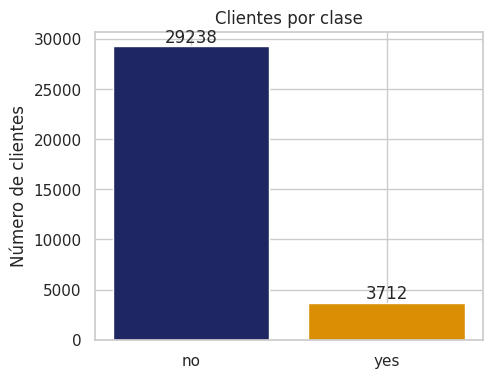

In [20]:
#  - una gráfica de barras con el número de clientes por clase.
fig, ax = plt.subplots(figsize=(5, 4))
barras = ax.bar(conteo.index, conteo.values, color=conteo.index.map(COLORES_CLASE))
ax.bar_label(barras)
ax.set_title("Clientes por clase")
ax.set_ylabel("Número de clientes")
plt.show()

**Tu observación.** Compara con tu predicción de las partes A y D y explica qué implica para la evaluación del modelo.

Mi predicción en la parte A fue que esperaba, por sentido común, un porcentaje de contrataciones menor al 10%, en la sección D nos dimos cuenta que el valor real es de aproximadamente de 11%.

Además, si un modelo contesta siempre "no", tiene una exactitud de 88.73%, por lo que al evaluar nuestro modelo, debemos obtener por lo menos este valor y tratar de mejorarlo.

### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.

**Tu predicción.** ¿Cuáles de las variables numéricas esperas que más difieran entre quienes contratan y quienes no?

Mi predicción es que se apreciará diferencia en las variables:
`age`: La edad es será un claro factor entre quienes contratan dependiendo de la fase de su vida.
`duration`: Llamadas largas se pueden asociar a clientes más interesados.
`campaign`: Un cliente que ha sido contactado muchas veces puede estar asociado a ser un cliente dificil de convencer
`previous`: Un cliente previamente contactado puede estar más cerca de contratar
`pdays`: Un cliente recientemente contactado puede estar más interesado en contratar.

In [21]:
# D2. Escribe el código que muestre:
#  - la mediana de cada variable numérica (lista numericas) por clase de y,
numericas = ["age", "duration", "campaign", "pdays", "previous", "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
print(ent.groupby("y")[numericas].median())


      age  duration  campaign  pdays  previous  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed
y                                                                                                                  
no   38.0     164.0       2.0  999.0       0.0           1.1          93.918          -41.8      4.857       5195.8
yes  37.0     448.0       2.0  999.0       0.0          -1.8          93.200          -40.4      1.266       5099.1


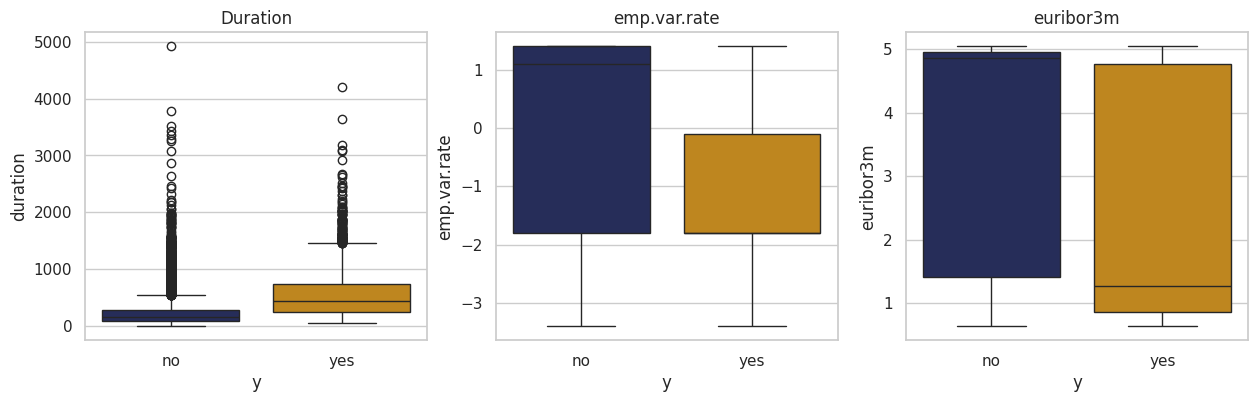

In [22]:
#  - diagramas de caja por clase de y de al menos tres variables numéricas que elijas.
eleccion = ['duration', 'emp.var.rate', 'euribor3m']

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=ent, x="y", y="duration", hue="y", order=["no", "yes"], palette=COLORES_CLASE, legend=False, ax=ejes[0])
sns.boxplot(data=ent, x="y", y="emp.var.rate", hue="y", order=["no", "yes"], palette=COLORES_CLASE, legend=False, ax=ejes[1])
sns.boxplot(data=ent, x="y", y="euribor3m", hue="y", order=["no", "yes"], palette=COLORES_CLASE, legend=False, ax=ejes[2])
ejes[0].set_title("Duration")
ejes[1].set_title("emp.var.rate")
ejes[2].set_title("euribor3m")
plt.show()

**Tu observación.** Indica qué variables separan las clases y cuáles no, con las medianas.

Intepretación: Las variables que muestran una mayor separación entre las clases según sus medianas son `duration`, `euribor3m` y `emp.var.rate`.

En particular, la duración de la llamada presenta la diferencia más marcada, con una mediana de 448 segundos para los clientes que contrataron frente a 164 segundos para los que no contrataron. Las variables `euribor3m` y `emp.var.rate` también muestran diferencias importantes, sugiriendo que las condiciones económicas podrían estar asociadas con la probabilidad de contratación.

### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** ¿Qué variables numéricas esperas que tengan más registros fuera de los límites de Tukey?

Por lo observado de los diagramas de cajas, podemos observar que `duration` presenta varios datos atípicos.
Adicionalmente, espero valores atípicos en `pdays`por la naturaleza del código 999 para gente que nunca ha sido contactada.

In [23]:
# D3. Escribe el código que calcule, con ent, los límites inferior y superior de Tukey

# de cada variable de la lista numericas y muestre cuántos registros quedan fuera de ellos por variable.

In [24]:
# D3. Cálculo de límites de Tukey y conteo de valores atípicos por variable en 'ent'
resultados_tukey = {}

for col in numericas:
    Q1 = ent[col].quantile(0.25)
    Q3 = ent[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR

    # Contar cuántos registros quedan fuera de los límites
    fuera_limites = ent[(ent[col] < limite_inf) | (ent[col] > limite_sup)].shape[0]

    resultados_tukey[col] = {
        'IQR': IQR,
        'Maximo': ent[col].max(),
        'Minimo': ent[col].min(),
        'Límite Inferior': limite_inf,
        'Límite Superior': limite_sup,
        'Atípicos (Conteo)': fuera_limites,
        'Porcentaje (%)': round((fuera_limites / len(ent)) * 100, 2)
    }

# Convertir a DataFrame para visualizarlo claramente
df_tukey = pd.DataFrame(resultados_tukey).T
print(df_tukey)

                    IQR    Maximo    Minimo  Límite Inferior  Límite Superior  Atípicos (Conteo)  Porcentaje (%)
age              15.000    98.000    17.000           9.5000          69.5000              368.0            1.12
duration        216.000  4918.000     0.000        -221.0000         643.0000             2366.0            7.18
campaign          2.000    56.000     1.000          -2.0000           6.0000             1916.0            5.81
pdays             0.000   999.000     0.000         999.0000         999.0000             1226.0            3.72
previous          0.000     7.000     0.000           0.0000           0.0000             4534.0           13.76
emp.var.rate      3.200     1.400    -3.400          -6.6000           6.2000                0.0            0.00
cons.price.idx    0.919    94.767    92.201          91.6965          95.3725                0.0            0.00
cons.conf.idx     6.300   -26.900   -50.800         -52.1500         -26.9500              359.0

**Tu respuesta.** ¿Eliminarías los registros atípicos de alguna variable?

En `age`, las edades extremas (17 y 98 años) son plausibles, por lo que se conservarían. En `campaign`, un número elevado de contactos puede reflejar clientes difíciles de convencer y no necesariamente un error de captura.

En `previous`, tener varios contactos previos también es una situación posible y aporta información útil. Para `pdays`, los valores detectados como atípicos se generan debido al código especial 999, que significa que el cliente no había sido contactado previamente, por lo que deben mantenerse.

En `cons.conf.idx`, los valores extremos forman parte de un indicador económico y no representan errores.

Las única variables donde consideraría una revisión adicional son `duration` y `campaign`, especialmente para llamadas con duración igual a 0 segundos, ya que podrían corresponder a registros sin interacción efectiva, y a clientes que han sido contactados muchas veces, como el caso del cliente con 56 contactos.

### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.** ¿Cuál transformación, raíz cuadrada o logaritmo (`np.log1p`), reducirá más la asimetría de `campaign`?

Espero una fuerte asimetría positiva, por lo que una función más agresiva como la logarítmica se espera como la más efectiva.

          Original   Raiz  Log1p
age          0.761  0.426  0.132
duration     3.327  1.204 -0.430
campaign     4.743  2.163  1.351



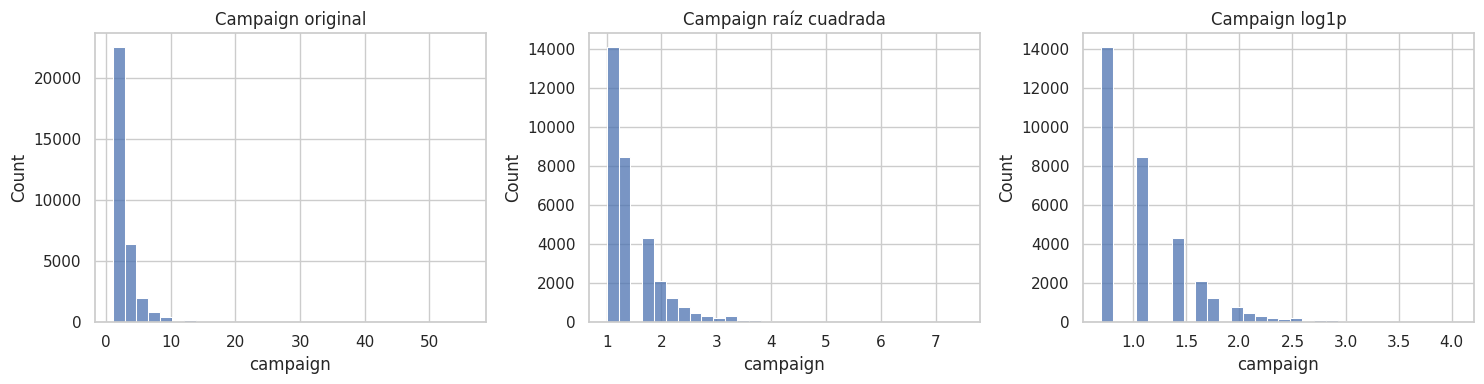

In [25]:
# D4. Escribe el código que muestre una tabla con la asimetría original, con raíz cuadrada y con
# logaritmo (np.log1p) de las variables age, duration y campaign, calculada con ent.
# Después grafica los histogramas de campaign: original y transformada.

# Asimetrías
asimetria = pd.DataFrame({
    "Original": ent[["age", "duration", "campaign"]].skew(),
    "Raiz": np.sqrt(ent[["age", "duration", "campaign"]]).skew(),
    "Log1p": np.log1p(ent[["age", "duration", "campaign"]]).skew()
}).round(3)

print(f"{asimetria}\n")

# Histogramas de campaign
fig, ejes = plt.subplots(1, 3, figsize=(15,4))

sns.histplot(ent["campaign"], bins=30, ax=ejes[0])
ejes[0].set_title("Campaign original")

sns.histplot(np.sqrt(ent["campaign"]), bins=30, ax=ejes[1])
ejes[1].set_title("Campaign raíz cuadrada")

sns.histplot(np.log1p(ent["campaign"]), bins=30, ax=ejes[2])
ejes[2].set_title("Campaign log1p")

plt.tight_layout()
plt.show()

**Tu observación.** Reporta las asimetrías y decide qué transformación, si alguna, aplicarías a cada variable.

Las tres variables presentan una asimetría positiva y presentan la mayor mejoría cuando se utiliza la función logarítmica.

## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** ¿Qué variable categórica esperas que tenga las categorías con mayor tasa de contratación? ¿Y cuáles esperas que casi no separen las clases? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

In [26]:
# E1. Escribe el código que muestre:
#  - el número de categorías de cada variable de la lista categoricas,
#  - la tasa global de contratación en ent.

print("Número de categorías por variable:")
for col in categoricas:
    print(f"{col}: {ent[col].nunique()}")

tasa_global = ent["suscribe"].mean() * 100
print(f"\nTasa global de contratación en ent: {tasa_global:.2f}%")

Número de categorías por variable:
job: 12
marital: 4
education: 8
default: 3
housing: 3
loan: 3
contact: 2
month: 10
day_of_week: 5
poutcome: 3

Tasa global de contratación en ent: 11.27%


In [27]:
# E2. Escribe el código que construya una tabla con el número de clientes y la tasa de contratación (en %)
# de cada categoría de cada variable de categoricas.

for c in categoricas:

    tabla = ent.groupby(c)["y"].agg(
        Clientes="count",
        Contratan=lambda x: (x == "yes").sum(),
        Tasa_Contratacion=lambda x: (x == "yes").mean() * 100
    ).round(2)

    tabla["% del total"] = (
        tabla["Contratan"] / len(ent) * 100
    ).round(2)

    tabla = tabla.sort_values("Tasa_Contratacion", ascending=False)

    # Agregar fila de totales
    tabla.loc["TOTAL", "Clientes"] = tabla["Clientes"].sum()
    tabla.loc["TOTAL", "Contratan"] = tabla["Contratan"].sum()
    tabla.loc["TOTAL", "Tasa_Contratacion"] = np.nan
    tabla.loc["TOTAL", "% del total"] = tabla["% del total"].sum().round(2)

    print(f"\n{'='*50}")
    print(c.upper())
    print(tabla)


JOB
               Clientes  Contratan  Tasa_Contratacion  % del total
job                                                               
student           711.0      217.0              30.52         0.66
retired          1366.0      348.0              25.48         1.06
unemployed        798.0      116.0              14.54         0.35
admin.           8314.0     1070.0              12.87         3.25
unknown           265.0       33.0              12.45         0.10
management       2345.0      269.0              11.47         0.82
technician       5400.0      585.0              10.83         1.78
self-employed    1099.0      119.0              10.83         0.36
housemaid         855.0       86.0              10.06         0.26
entrepreneur     1160.0      100.0               8.62         0.30
services         3196.0      254.0               7.95         0.77
blue-collar      7441.0      515.0               6.92         1.56
TOTAL           32950.0     3712.0                NaN    

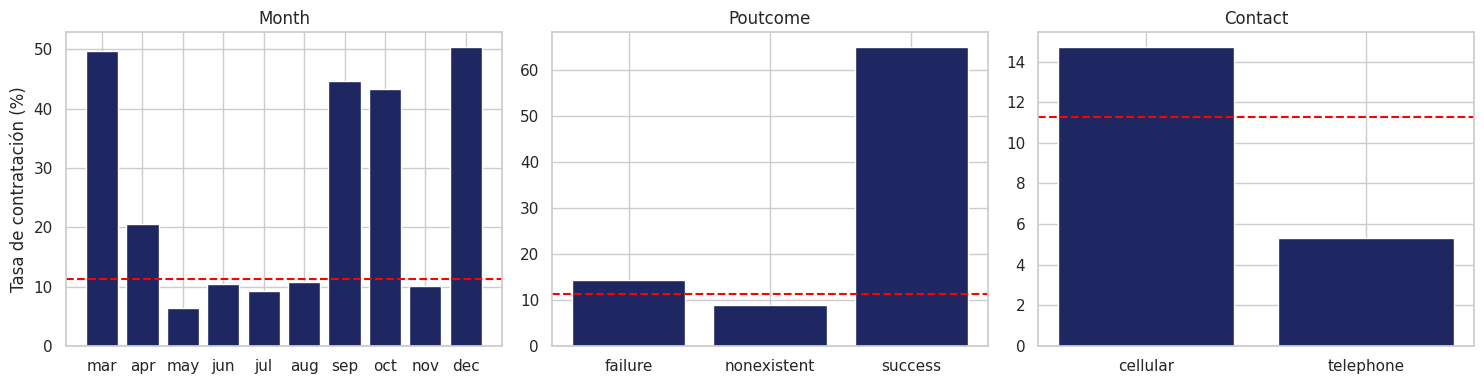

In [28]:
# E3. Escribe el código que grafique la tasa de contratación por categoría de month (en orden
# cronológico: mar, apr, may, jun, jul, aug, sep, oct, nov, dec), poutcome y contact,
# con una línea horizontal en la tasa global.

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))

# Month
orden_mes = ["mar", "apr", "may", "jun", "jul",
             "aug", "sep", "oct", "nov", "dec"]

mes = (
    ent.groupby("month")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .reindex(orden_mes)
)

ejes[0].bar(mes.index, mes.values, color=AZUL)
ejes[0].axhline(tasa_global, color="red", linestyle="--")
ejes[0].set_title("Month")
ejes[0].set_ylabel("Tasa de contratación (%)")

# Poutcome
poutcome = (
    ent.groupby("poutcome")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
)

ejes[1].bar(poutcome.index, poutcome.values, color=AZUL)
ejes[1].axhline(tasa_global, color="red", linestyle="--")
ejes[1].set_title("Poutcome")

# Contact
contact = (
    ent.groupby("contact")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
)

ejes[2].bar(contact.index, contact.values, color=AZUL)
ejes[2].axhline(tasa_global, color="red", linestyle="--")
ejes[2].set_title("Contact")

plt.tight_layout()
plt.show()

**Tu observación.** Identifica las categorías con mayor y menor tasa, con su tasa y su número de clientes, y las variables que casi no separan las clases.

Encontramos en la mayoría de las columnas categóricas tasas de contratación bien distribuidas, con valores cercanos a la tasa global.

Posibles categóricas de interés son `job`, que si bien, tiene bien distribuidas sus tasas de contratación, encontramos dos categorías con tasas muy altas: `studen` con 30.52% y `retired` con 16.92%.

Otra columna muy interesante es `month` como se ve en las gráficas anteriores. Tasas de contratación muy superiores a la global en los meses de diciembre, marzo, septiembre y octubre.

**Tu respuesta.** En `default`, ¿qué indica que la categoría `unknown` tenga una tasa de contratación distinta a la de `no`? ¿Qué hay que cuidar con las categorías `yes` de `default` o `illiterate` de `education`?

Para el caso específico de `unknown` en `default`, la diferencia en tasas de contratación nos confirma que se trata de categorías diferentes y validas. Podemos especular que `unknown` son clientes que no quisieron decir que sí tienen deudas, esto a su vez explica la falta de registros con `yes` en esta columna.

Para `yes` e `illiterate` hay que cuidar que si bien tienen tasas de contratación altas, la cantidad de registros es muy pequeña, no hay suficiente evidencia para decir que es un separador de clases.

## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** ¿Qué pares de indicadores económicos (lista `macro`) esperas que estén más correlacionados?

Espero relaciones entre indicadores de fuerza de la economía y otros indicadores que mejoran/empeoran dependiendo de la economía. Esto es pares como: `emp.var.rate` y `euribor3m`, o `emp.var.rate` con `cons.conf.idx`.

También otras correlaciones un poco más obvias como `emp.var.rate` y `nr.employed`.

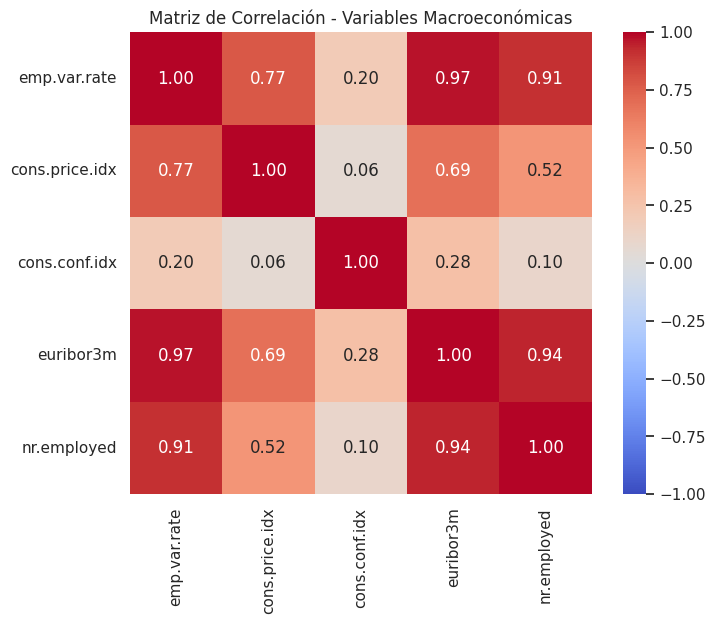

In [29]:
# F1. Escribe el código que muestre un mapa de calor con la matriz de correlación de las variables de la lista macro,
# calculada con ent, con los valores anotados en cada celda.

matriz_corr = ent[macro].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Matriz de Correlación - Variables Macroeconómicas")
plt.show()

**Tu observación.** Reporta los pares más correlacionados y la decisión que implican.

`emp.var.rate` se correlaciona en 0.97 con `euribor3m`, un 0.91 con `nr.employed`.
`euribor3m` se correlaciona en 0.94 con `nr.employed`.
Sugiere que estas variables describen aspectos similares del estado de la economía: cuando aumenta el empleo, también tienden a aumentar las tasas de interés y el número de personas empleadas.


Finalmente `cons.price.idx` se corrrelaciona en un 0.77 con `emp.var.rate`, y en 0.69 con `euribor3m`. Indicando que los niveles de precios también están relacionados con la actividad económica general

### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.

In [30]:
# F2. Escribe el código que muestre el resumen estadístico (describe) de duration por clase de y.

display(ent.groupby("y")["duration"].describe())

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,29238.0,221.148198,208.303557,0.0,95.0,164.0,279.0,4918.0
yes,3712.0,549.398976,397.490060,63.0,252.0,448.0,737.0,4199.0


**Tu respuesta.** ¿Incluirías `duration` como característica de un modelo que se usará para decidir a quién llamar? Justifica con la definición de la variable y con lo observado.

La variable duration representa la duración de la llamada realizada al cliente, por lo que solo se conoce después de haber efectuado el contacto. Además, en el análisis se observó que es una de las variables que más diferencian a quienes contratan de quienes no, pero precisamente porque contiene información generada durante la llamada.

**Tu respuesta.** El conjunto está ordenado por fecha y los indicadores económicos varían con el tiempo. ¿Qué implica dividir al azar, como en la parte C, para un modelo que se usará en campañas futuras?

Dividir al azar mezcla registros de distintos momentos en entrenamiento y prueba. Como las variables macroeconómicas cambian con el tiempo, esto puede hacer que el modelo vea durante el entrenamiento condiciones económicas muy parecidas a las del conjunto de prueba. En una campaña futura no se tendrá acceso a información del futuro, por lo que la evaluación podría resultar demasiado optimista. Para un escenario realista sería preferible entrenar con datos más antiguos y evaluar con datos más recientes

## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.


| Hallazgo (con cifra) | Decisión | Se aplica en |
|----------------------|-----------|--------------|
| Solo 11.27% de los clientes contratan (`yes`) frente a 88.73% que no contratan (`no`). | Considerar técnicas para tratar el desbalance de clases (ponderación de clases o métricas distintas de accuracy). | Modelos / Evaluación |
| Existen 12 registros duplicados. | Eliminar duplicados conservando la primera aparición. | Preprocesamiento |
| La variable `default` contiene 20.87% de valores `unknown`. | Mantener `unknown` como una categoría válida. | Preprocesamiento |
| La variable `pdays` contiene 96.23% de valores `999`, código que significa que el cliente no fue contactado previamente. | Mantener el código 999 o transformarlo en una categoría específica, no tratarlo como dato faltante. | Preprocesamiento |
| Se detectaron registros con `pdays = 999` y `poutcome = failure`, una posible inconsistencia. | Conservar los registros y documentar la incidencia por falta de evidencia para corregirlos. | Preprocesamiento |
| `duration` presenta una fuerte diferencia entre clases (medianas de 164 y 448 segundos) pero solo se conoce después de la llamada. | Excluir `duration` del modelo predictivo para evitar fuga de información. | Modelos |
| `campaign` presenta alta asimetría (4.74), reducida a 1.35 mediante `log1p`. | Aplicar transformación logarítmica si el modelo es sensible a la distribución de las variables. | Preprocesamiento |
| `emp.var.rate` y `euribor3m` tienen correlación de 0.97; `euribor3m` y `nr.employed` de 0.94. | Revisar posible multicolinealidad y considerar eliminar alguna variable redundante. | Modelos |
| Existen 4 llamadas con duración igual a 0 segundos. | Eliminar esos registros al no representar una interacción efectiva. | Preprocesamiento |

### G2. Uso de los datos

**Tu respuesta.** En esta actividad, ¿qué partes se hicieron con el conjunto total y cuáles solo con entrenamiento?

Las revisiones de calidad de datos, como tipos de datos, duplicados y códigos especiales, se realizaron sobre el conjunto completo. En cambio, el análisis relacionado con la variable objetivo `y`, como tasas de contratación y comparación entre clases, se hizo únicamente con entrenamiento para evitar fuga de información.

**Tu respuesta.** Si hubieras explorado también el conjunto de prueba, ¿qué decisión de tu hoja podría quedar sesgada y cómo se reflejaría en la evaluación final?

Podría sesgarse la selección de variables importantes, por ejemplo concluir qué variables separan mejor las clases. Esto haría que el modelo se adaptara indirectamente al conjunto de prueba y la evaluación final parecería mejor de lo que realmente sería con datos nuevos.